In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
import joblib

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [2]:
processed_path = Path("../dataset/processed")

X_train = np.load(processed_path / "X_train_scaled.npy")
X_test = np.load(processed_path / "X_test_scaled.npy")

y_train = np.load(processed_path / "y_train.npy")
y_test = np.load(processed_path / "y_test.npy")

In [3]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("Classes:", len(np.unique(y_train)))

Training features: (51500, 63)
Testing features: (12876, 63)
Training labels: (51500,)
Testing labels: (12876,)
Classes: 28


In [5]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

In [6]:
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

In [7]:
knn_model.fit(X_train, y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U7](28,)","['A','B','C',...,'W','X','Y']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [8]:
knn_model.fit(X_train, y_train)

,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[<U7](28,)","['A','B','C',...,'W','X','Y']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [9]:
y_pred_knn = knn_model.predict(X_test)

In [10]:
print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred_knn[:10])

Actual labels: ['B' 'L' 'Space' 'R' 'W' 'K' 'J' 'U' 'B' 'B']
Predicted labels: ['B' 'L' 'Space' 'R' 'W' 'K' 'J' 'U' 'B' 'B']


In [11]:
from sklearn.metrics import accuracy_score

In [12]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy * 100, "%")

KNN Accuracy: 99.83690587138862 %


In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       534
           B       1.00      1.00      1.00       542
           C       1.00      1.00      1.00       447
     Confirm       1.00      1.00      1.00       557
           D       1.00      1.00      1.00       510
           E       1.00      1.00      1.00       500
           F       1.00      1.00      1.00       535
           G       1.00      1.00      1.00       472
           H       1.00      1.00      1.00       586
           I       1.00      1.00      1.00       466
           J       1.00      1.00      1.00       523
           K       1.00      0.99      1.00       385
           L       1.00      1.00      1.00       430
           M       1.00      1.00      1.00       446
           N       1.00      1.00      1.00       509
           O       1.00      1.00      1.00       501
           P       1.00      1.00      1.00       371
           Q       1.00    

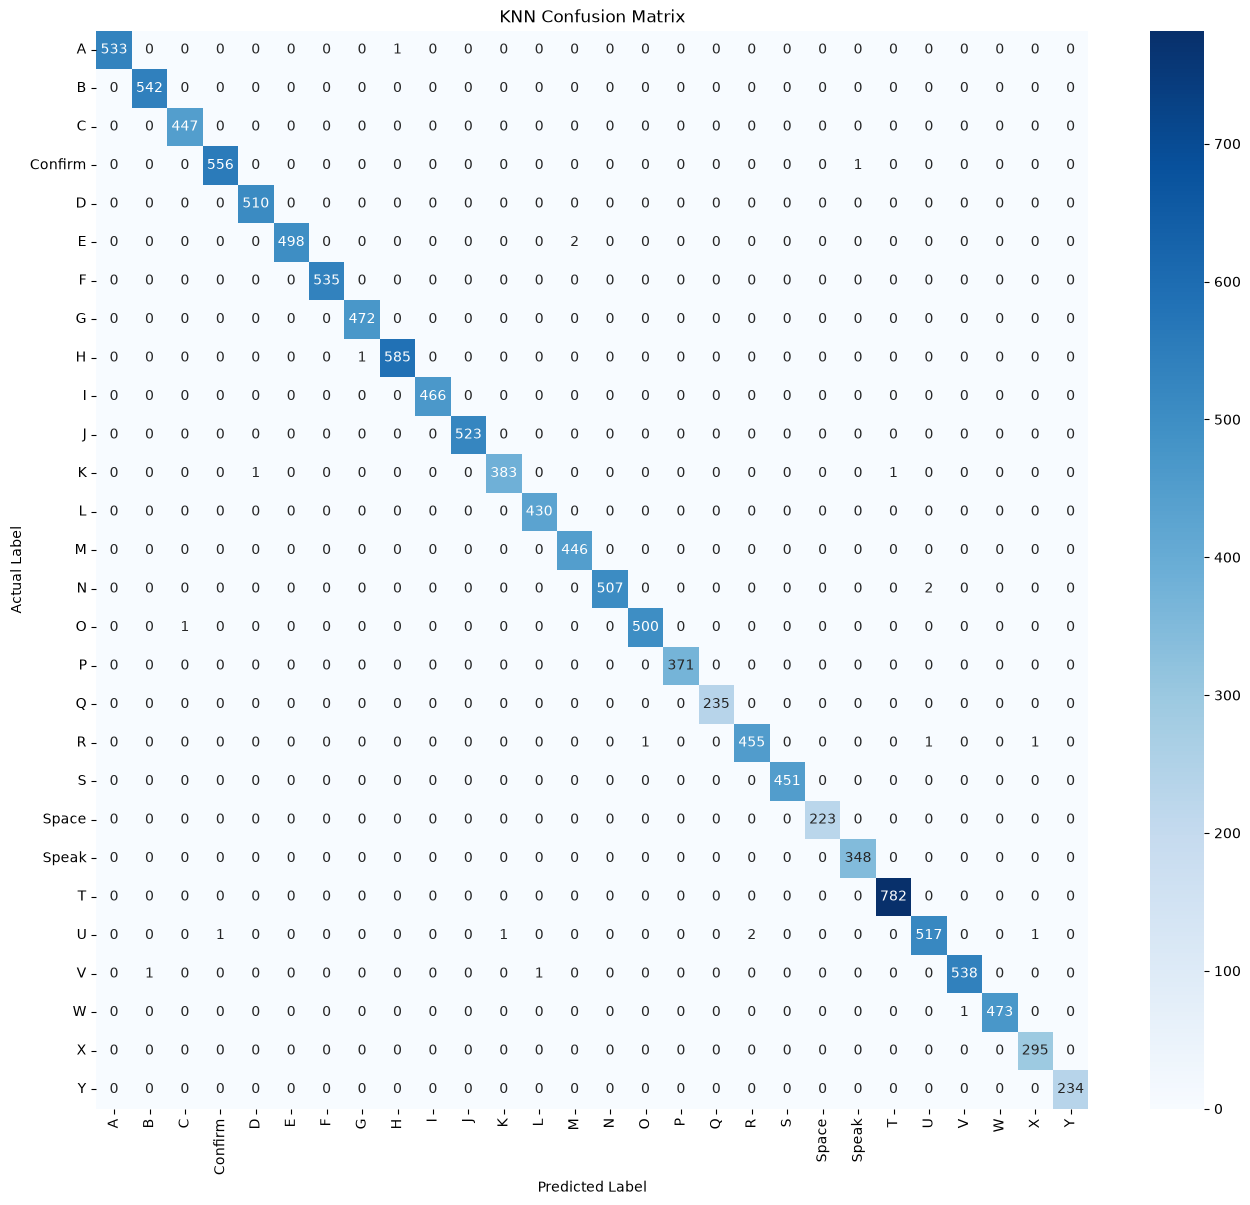

In [14]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_knn, labels=knn_model.classes_)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=knn_model.classes_,
    yticklabels=knn_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("KNN Confusion Matrix")
plt.show()

In [15]:
n_neighbors=5
metric="euclidean"

In [16]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

In [17]:
k_values = [3, 5, 7, 9]

for k in k_values:

    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean"
    )

    scores = cross_val_score(
        knn,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    print("K =", k)
    print("Fold scores:", scores)
    print("Mean accuracy:", scores.mean() * 100)
    print("-------------------------")

K = 3
Fold scores: [0.99815534 0.99873786 0.99805825 0.99854369 0.99796117]
Mean accuracy: 99.82912621359225
-------------------------
K = 5
Fold scores: [0.99805825 0.99834951 0.99757282 0.99825243 0.99718447]
Mean accuracy: 99.7883495145631
-------------------------
K = 7
Fold scores: [0.99718447 0.99776699 0.99650485 0.9976699  0.99699029]
Mean accuracy: 99.72233009708738
-------------------------
K = 9
Fold scores: [0.99669903 0.99757282 0.99660194 0.99747573 0.99660194]
Mean accuracy: 99.69902912621359
-------------------------


In [18]:
best_knn = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean"
)

best_knn.fit(X_train, y_train)

y_pred_knn_best = best_knn.predict(X_test)

best_knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn_best
)

print("Best K:", 3)
print("Test Accuracy:", best_knn_accuracy * 100, "%")

Best K: 3
Test Accuracy: 99.8524386455421 %


In [19]:
best_knn = KNeighborsClassifier(
    n_neighbors=3,
    metric="euclidean"
)

best_knn.fit(X_train, y_train)

y_pred_knn_best = best_knn.predict(X_test)

best_knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn_best
)

print("Best K:", 3)
print("Test Accuracy:", best_knn_accuracy * 100, "%")

Best K: 3
Test Accuracy: 99.8524386455421 %


In [20]:
# 2. Support Vector Machine (SVM)
from sklearn.svm import SVC


In [21]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

In [22]:
svm_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [23]:
svm_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [24]:
y_pred_svm = svm_model.predict(X_test)

In [25]:
print("Actual labels:", y_test[:10])
print("Predicted labels:", y_pred_svm[:10])

Actual labels: ['B' 'L' 'Space' 'R' 'W' 'K' 'J' 'U' 'B' 'B']
Predicted labels: ['B' 'L' 'Space' 'R' 'W' 'K' 'J' 'U' 'B' 'B']


In [26]:
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy * 100, "%")

SVM Accuracy: 99.84467225846537 %


In [27]:
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       534
           B       1.00      1.00      1.00       542
           C       1.00      1.00      1.00       447
     Confirm       1.00      1.00      1.00       557
           D       1.00      1.00      1.00       510
           E       1.00      1.00      1.00       500
           F       1.00      1.00      1.00       535
           G       1.00      1.00      1.00       472
           H       1.00      1.00      1.00       586
           I       1.00      1.00      1.00       466
           J       1.00      1.00      1.00       523
           K       1.00      0.99      1.00       385
           L       1.00      1.00      1.00       430
           M       1.00      1.00      1.00       446
           N       1.00      1.00      1.00       509
           O       1.00      1.00      1.00       501
           P       0.99      1.00      1.00       371
           Q       1.00    

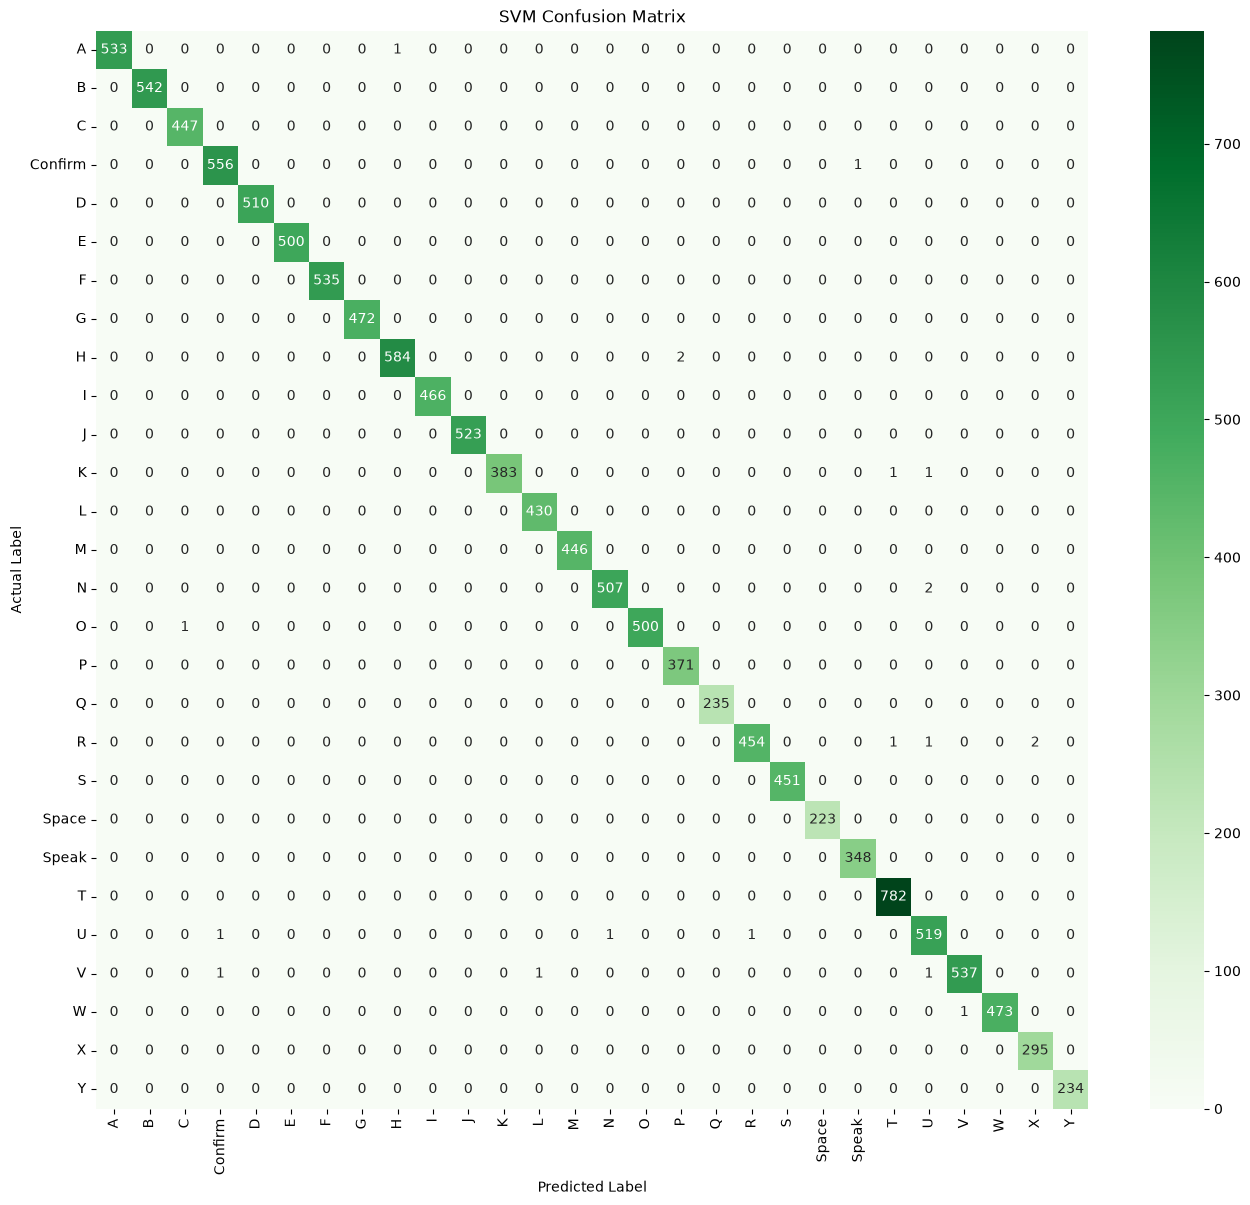

In [28]:
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=svm_model.classes_
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")
plt.show()

In [30]:
#descision tree

from sklearn.tree import DecisionTreeClassifier

In [31]:
from sklearn.tree import DecisionTreeClassifier

In [32]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    random_state=42
)

In [33]:
dt_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [34]:
y_pred_dt = dt_model.predict(X_test)

In [35]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy * 100, "%")

Decision Tree Accuracy: 99.07579993786891 %


In [36]:
max_depth=None

In [37]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           A       1.00      0.99      0.99       534
           B       0.99      0.99      0.99       542
           C       1.00      1.00      1.00       447
     Confirm       0.98      0.98      0.98       557
           D       0.99      1.00      1.00       510
           E       1.00      0.99      0.99       500
           F       1.00      1.00      1.00       535
           G       1.00      1.00      1.00       472
           H       0.99      0.99      0.99       586
           I       0.99      1.00      1.00       466
           J       1.00      0.99      0.99       523
           K       0.99      0.97      0.98       385
           L       0.99      0.99      0.99       430
           M       0.98      0.99      0.99       446
           N       0.99      0.98      0.98       509
           O       1.00      1.00      1.00       501
           P       0.99      0.99      0.99       371
           Q       1.00    

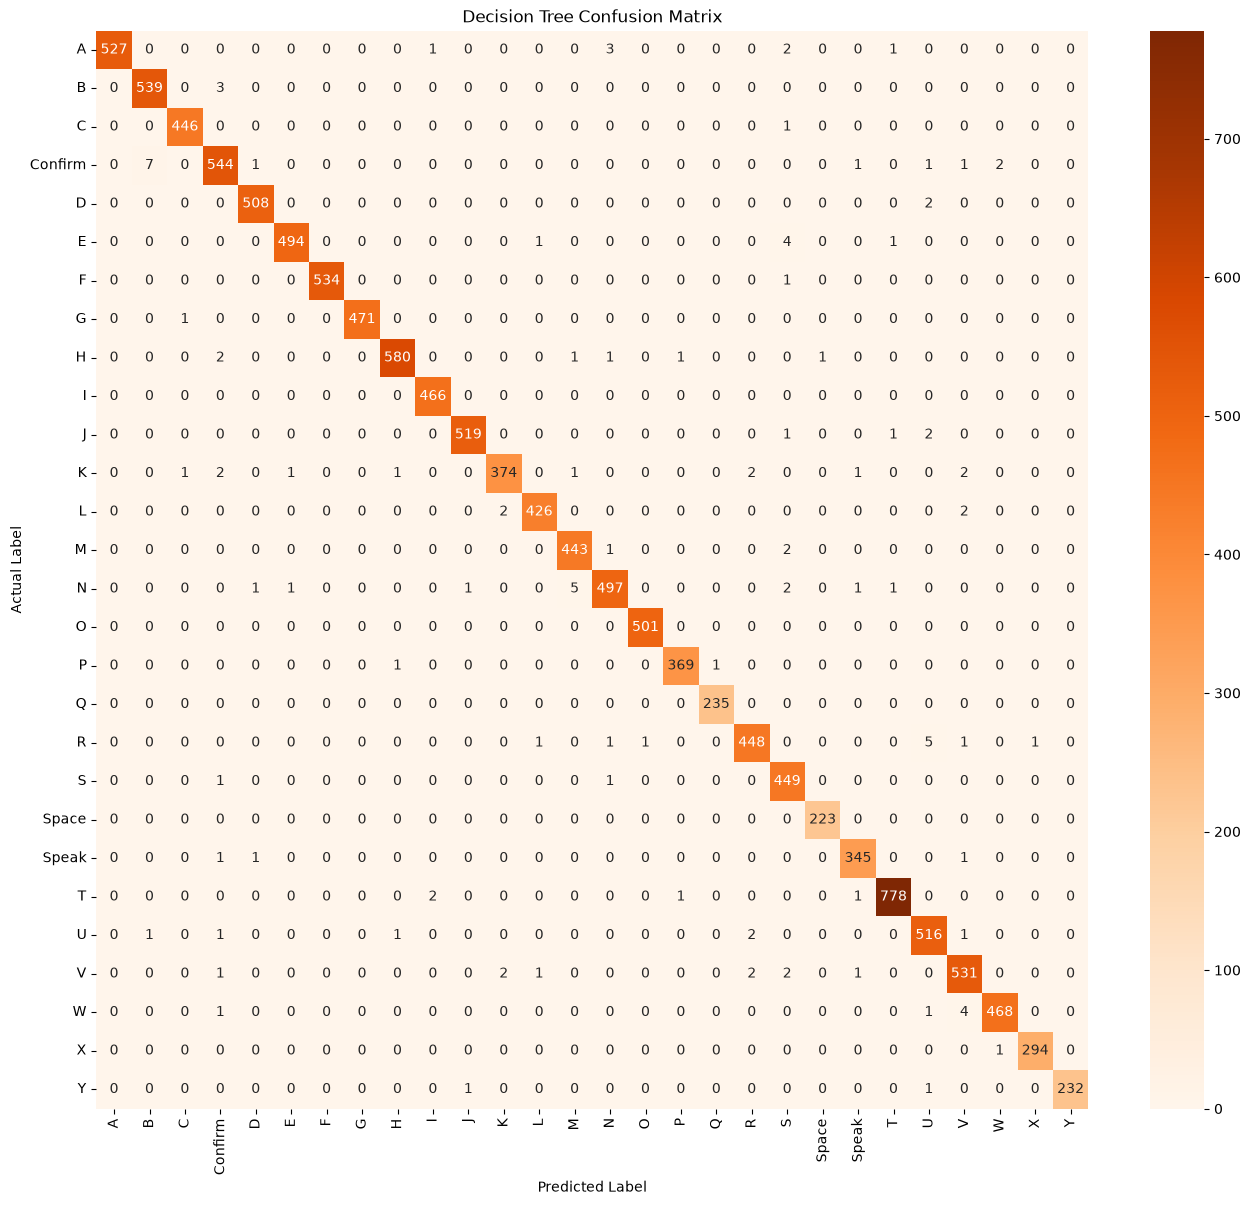

In [38]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=dt_model.classes_
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [39]:
# 4. Random Forest
from sklearn.ensemble import RandomForestClassifier


In [40]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

In [41]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

In [42]:
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [43]:
y_pred_rf = rf_model.predict(X_test)

In [44]:
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy * 100, "%")

Random Forest Accuracy: 99.86797141969555 %


In [45]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       534
           B       1.00      1.00      1.00       542
           C       1.00      1.00      1.00       447
     Confirm       1.00      1.00      1.00       557
           D       1.00      1.00      1.00       510
           E       1.00      1.00      1.00       500
           F       1.00      1.00      1.00       535
           G       1.00      1.00      1.00       472
           H       1.00      1.00      1.00       586
           I       1.00      1.00      1.00       466
           J       1.00      1.00      1.00       523
           K       0.99      0.99      0.99       385
           L       1.00      1.00      1.00       430
           M       1.00      1.00      1.00       446
           N       1.00      1.00      1.00       509
           O       1.00      1.00      1.00       501
           P       0.99      1.00      1.00       371
           Q       1.00    

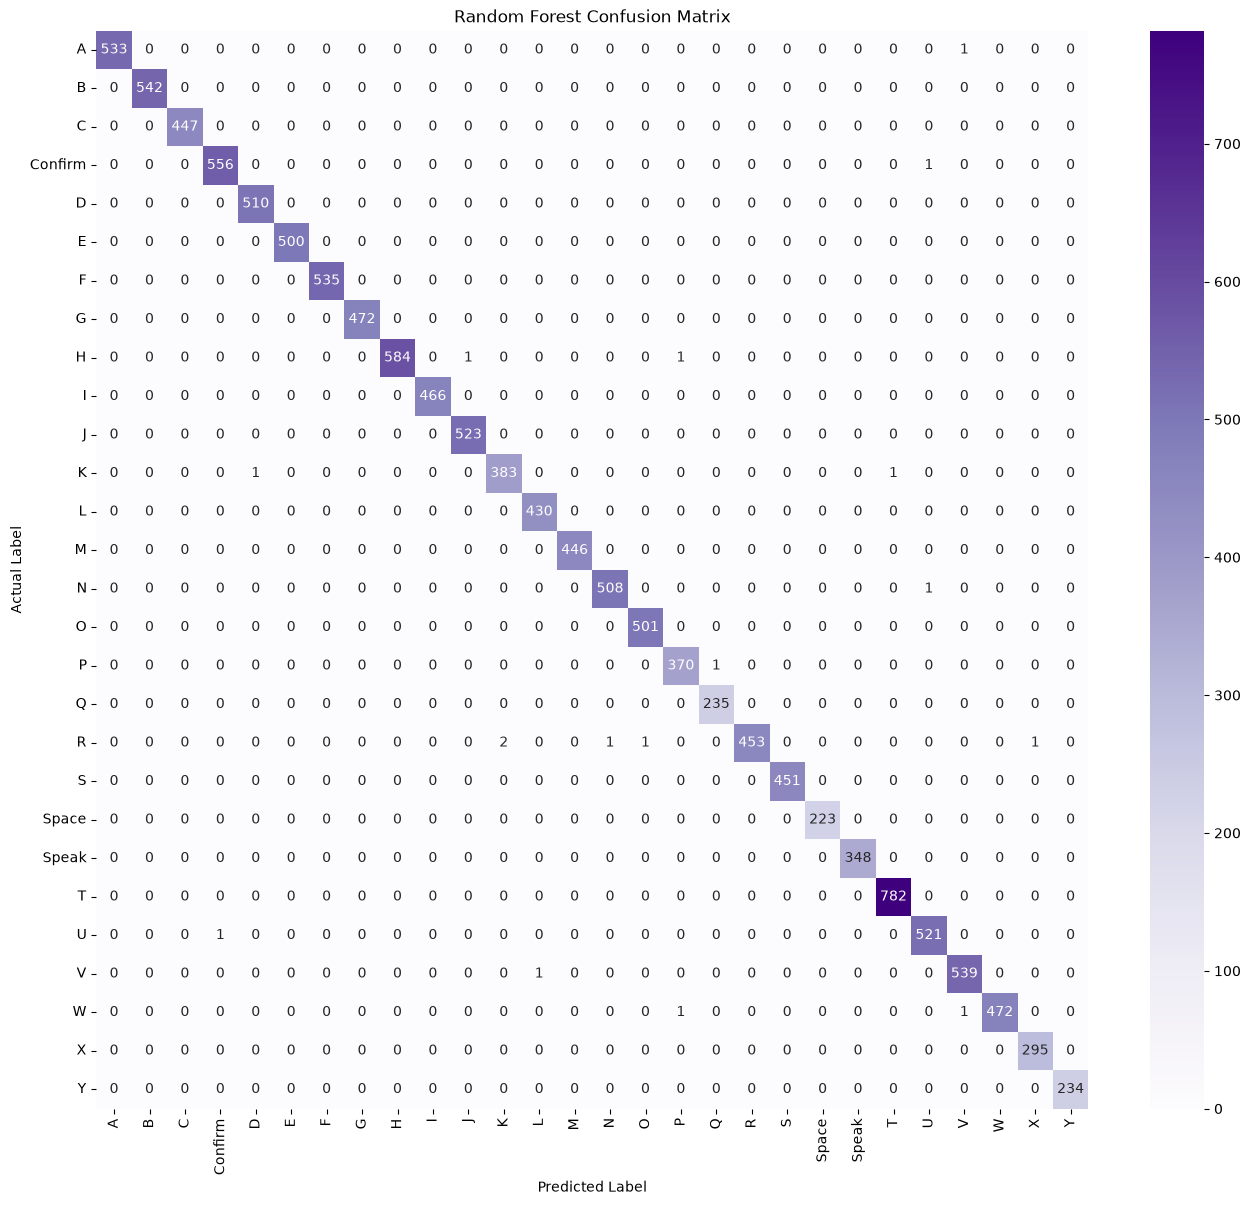

In [46]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=rf_model.classes_
)

plt.figure(figsize=(16, 14))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [47]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       534
           B       1.00      1.00      1.00       542
           C       1.00      1.00      1.00       447
     Confirm       1.00      1.00      1.00       557
           D       1.00      1.00      1.00       510
           E       1.00      1.00      1.00       500
           F       1.00      1.00      1.00       535
           G       1.00      1.00      1.00       472
           H       1.00      1.00      1.00       586
           I       1.00      1.00      1.00       466
           J       1.00      1.00      1.00       523
           K       0.99      0.99      0.99       385
           L       1.00      1.00      1.00       430
           M       1.00      1.00      1.00       446
           N       1.00      1.00      1.00       509
           O       1.00      1.00      1.00       501
           P       0.99      1.00      1.00       371
           Q       1.00    

In [48]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       534
           B       1.00      1.00      1.00       542
           C       1.00      1.00      1.00       447
     Confirm       1.00      1.00      1.00       557
           D       1.00      1.00      1.00       510
           E       1.00      1.00      1.00       500
           F       1.00      1.00      1.00       535
           G       1.00      1.00      1.00       472
           H       1.00      1.00      1.00       586
           I       1.00      1.00      1.00       466
           J       1.00      1.00      1.00       523
           K       0.99      0.99      0.99       385
           L       1.00      1.00      1.00       430
           M       1.00      1.00      1.00       446
           N       1.00      1.00      1.00       509
           O       1.00      1.00      1.00       501
           P       0.99      1.00      1.00       371
           Q       1.00    

In [49]:
results = pd.DataFrame({
    "Algorithm": [
        "KNN",
        "SVM",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy (%)": [
        knn_accuracy * 100,
        svm_accuracy * 100,
        dt_accuracy * 100,
        rf_accuracy * 100
    ]
})

results = results.sort_values(
    by="Accuracy (%)",
    ascending=False
)

print(results)

       Algorithm  Accuracy (%)
3  Random Forest     99.867971
1            SVM     99.844672
0            KNN     99.836906
2  Decision Tree     99.075800


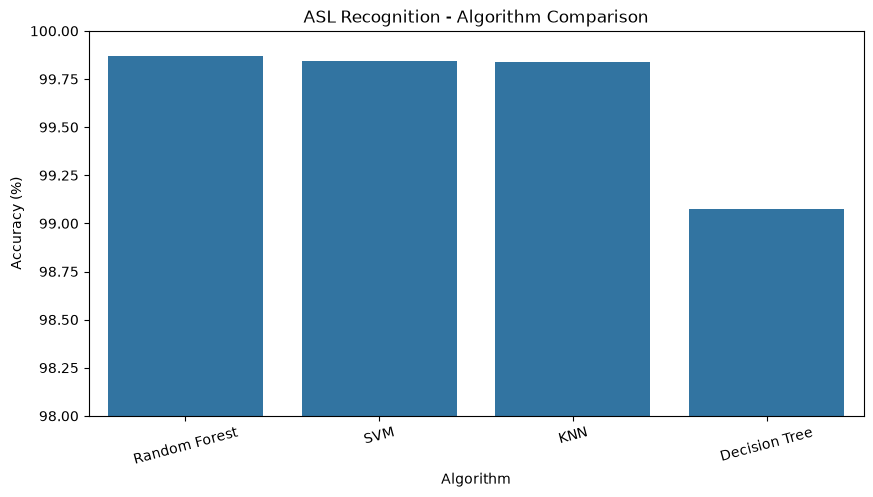

In [50]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x="Algorithm",
    y="Accuracy (%)"
)

plt.title("ASL Recognition - Algorithm Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(98, 100)
plt.xticks(rotation=15)
plt.show()

In [51]:
#Training time and prediction time
import time

In [52]:
models = {
    "KNN": KNeighborsClassifier(n_neighbors=3, metric="euclidean"),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Decision Tree": DecisionTreeClassifier(
        criterion="gini", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        criterion="gini",
        random_state=42,
        n_jobs=-1
    )
}

time_results = []

for name, model in models.items():

    start_time = time.time()

    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    start_time = time.time()

    model.predict(X_test)

    prediction_time = time.time() - start_time

    time_results.append({
        "Algorithm": name,
        "Training Time (s)": training_time,
        "Prediction Time (s)": prediction_time
    })

time_df = pd.DataFrame(time_results)

print(time_df)

       Algorithm  Training Time (s)  Prediction Time (s)
0            KNN           0.022517             1.296660
1            SVM          13.081911            17.632233
2  Decision Tree           8.270700             0.006001
3  Random Forest           8.548501             0.135869


In [53]:
from pathlib import Path
import subprocess

project_root = Path(r"C:\Users\ASUS\Desktop\AMINDRA\American Sign Language")

print("Folder exists:", project_root.exists())
print("Project location:", project_root)

Folder exists: True
Project location: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language


In [54]:
def run_git(command):
    result = subprocess.run(
        ["git", "-C", str(project_root)] + command,
        capture_output=True,
        text=True
    )
    print(result.stdout if result.stdout else result.stderr)

run_git(["status"])

fatal: not a git repository (or any of the parent directories): .git



In [55]:
from pathlib import Path
import subprocess

project_root = Path(r"C:\Users\ASUS\Desktop\AMINDRA\American Sign Language")

def run_git(command):
    result = subprocess.run(
        ["git", "-C", str(project_root)] + command,
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)

run_git(["status"])


fatal: not a git repository (or any of the parent directories): .git



In [56]:
run_git(["remote", "-v"])


fatal: not a git repository (or any of the parent directories): .git



In [57]:
run_git(["branch", "--show-current"])


fatal: not a git repository (or any of the parent directories): .git



In [58]:
run_git(["init"])

Initialized empty Git repository in C:/Users/ASUS/Desktop/AMINDRA/American Sign Language/.git/



In [59]:
run_git(["status"])

On branch master

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	dataset/
	media_pipe_keypoints_dataset/
	notebooks/

nothing added to commit but untracked files present (use "git add" to track)



In [60]:
gitignore_content = """
# Original dataset
media_pipe_keypoints_dataset/

# Processed datasets
dataset/processed/

# Python
__pycache__/
*.pyc
.ipynb_checkpoints/

# Jupyter temporary files
*.tmp

# Environment files
.env
.venv/
venv/

# Model files
models/*.pkl
models/*.joblib
"""

gitignore_path = project_root / ".gitignore"

gitignore_path.write_text(
    gitignore_content.strip() + "\n",
    encoding="utf-8"
)

print("Created:", gitignore_path)
print("Exists:", gitignore_path.exists())

Created: C:\Users\ASUS\Desktop\AMINDRA\American Sign Language\.gitignore
Exists: True


In [61]:
run_git(["status"])

On branch master

No commits yet

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore
	notebooks/

nothing added to commit but untracked files present (use "git add" to track)



In [62]:
run_git(["check-ignore", "-v", "media_pipe_keypoints_dataset/A"])
run_git(["check-ignore", "-v", "dataset/processed"])

.gitignore:2:media_pipe_keypoints_dataset/	media_pipe_keypoints_dataset/A

.gitignore:5:dataset/processed/	dataset/processed



In [63]:
for file in (project_root / "notebooks").glob("*"):
    if file.is_file():
        print(file.name, f"({file.stat().st_size / 1024:.1f} KB)")

01_dataset_understanding.ipynb (180.2 KB)
03_preprocessing.ipynb (30.0 KB)
04_model_training.ipynb (1050.0 KB)


In [64]:
run_git(["remote", "-v"])

In [65]:
run_git([
    "remote",
    "add",
    "origin",
    "https://github.com/Amindra-Edirisuriya/American-Sign-Language-Ditection.git"
])

In [66]:
run_git(["remote", "-v"])

origin	https://github.com/Amindra-Edirisuriya/American-Sign-Language-Ditection.git (fetch)
origin	https://github.com/Amindra-Edirisuriya/American-Sign-Language-Ditection.git (push)



In [67]:
run_git(["branch", "-M", "main"])

In [68]:
run_git(["add", "."])

In [69]:
run_git(["status"])

On branch main

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .gitignore
	new file:   notebooks/01_dataset_understanding.ipynb
	new file:   notebooks/03_preprocessing.ipynb
	new file:   notebooks/04_model_training.ipynb




In [70]:
run_git([
    "commit",
    "-m",
    "Initial commit: ASL recognition project notebooks"
])

[main (root-commit) 5decc22] Initial commit: ASL recognition project notebooks
 4 files changed, 12985 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 notebooks/01_dataset_understanding.ipynb
 create mode 100644 notebooks/03_preprocessing.ipynb
 create mode 100644 notebooks/04_model_training.ipynb



In [71]:
run_git(["push", "-u", "origin", "main"])

branch 'main' set up to track 'origin/main'.

To https://github.com/Amindra-Edirisuriya/American-Sign-Language-Ditection.git
 * [new branch]      main -> main



In [ ]:
# 1. Check changes
run_git(["status"])

# 2. Stage changes
run_git(["add", "."])

# 3. Commit changes
run_git(["commit", "-m", "Describe your changes"])

# 4. Push to GitHub
run_git(["push"])